In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

## Random Samples ##

We load in a dataset of all United flights national flights from 6/1/15 to 8/9/15, their destination, and how long they were delayed in minutes.

In [2]:
united = Table.read_table('united.csv')
united = united.with_column('Row', np.arange(0, united.num_rows))
united

Date,Flight Number,Destination,Delay,Row
6/1/15,73,HNL,257,0
6/1/15,217,EWR,28,1
6/1/15,237,STL,-3,2
6/1/15,250,SAN,0,3
6/1/15,267,PHL,64,4
6/1/15,273,SEA,-6,5
6/1/15,278,SEA,-8,6
6/1/15,292,EWR,12,7
6/1/15,300,HNL,20,8
6/1/15,317,IND,-10,9


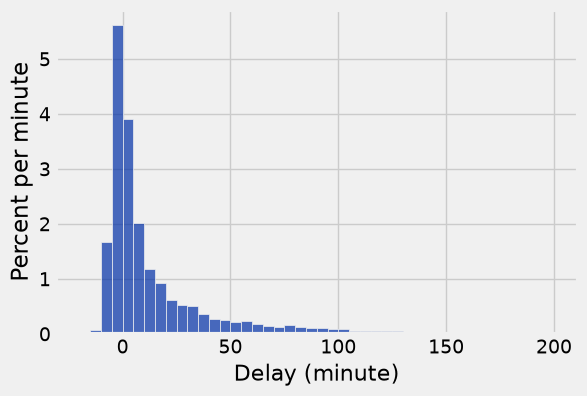

In [3]:
# Probability Distribution (assuming this is the entire population)
united_bins = np.arange(-20, 201, 5)
united.hist('Delay', bins = united_bins, unit = 'minute')

In [5]:
# Empirical Distribution of 10 flights
united_sample = united.sample(10)
united_sample

Date,Flight Number,Destination,Delay,Row
8/27/15,1570,BOS,0,13205
8/5/15,1608,EWR,21,9908
7/30/15,486,IAD,-6,8896
7/7/15,1683,EWR,44,5456
6/13/15,1401,SAN,2,1892
6/3/15,322,SEA,-6,307
8/24/15,1556,LAS,6,12756
7/19/15,1591,ORD,7,7273
8/11/15,1124,SEA,-5,10804
7/6/15,1073,BOS,19,5236


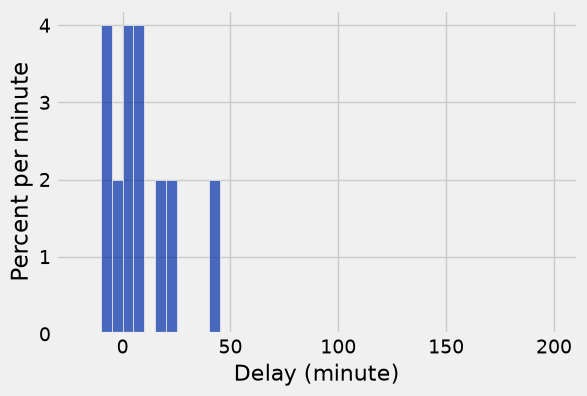

In [6]:
united_sample.hist('Delay', bins = united_bins, unit = 'minute')

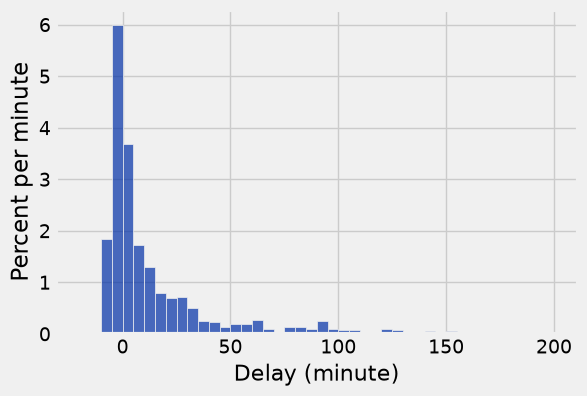

In [7]:
# Empirical Distribution of 1,000 flights
united_sample1000 = united.sample(1000)
united_sample1000.hist('Delay', bins = united_bins, unit = 'minute')

## Simulating Statistics ##

In [8]:
# Population Parameter
delays_arr = united.column('Delay')
np.median(delays_arr)

2.0

### Practice


In [13]:
def sample_median(size):
    # Sample the united table. Get the number of rows specified by the parameter.
    # Get the 'Delay' column'
    # Return the median.
    sample_united = united.sample(size)
    delay_column = sample_united.column('Delay')
    samp_median = np.median(delay_column)
    return(samp_median)

In [42]:
# Test a few times with a sample of size 10.
sample_median(10)

17.5

In [53]:
# Test a few times with a sample of size 1000.
sample_median(1000)

2.0

## Empirical Distribution of a Statistic ##

### Practice

Use sample_medians(10) to simulate the median 1000 times using a sample of size 10. Store all the simulated medians in an array and visualize with a histogram.

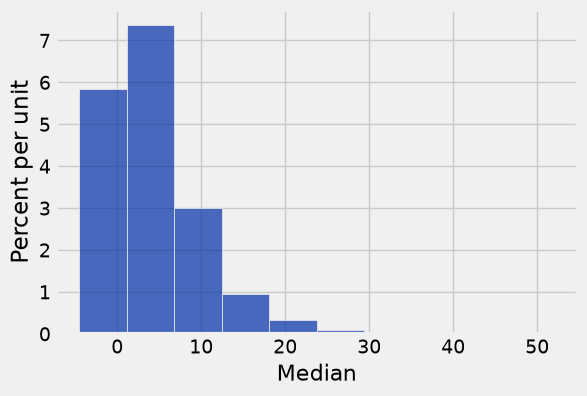

In [76]:
medians_arr = make_array()

for i in range(1000):
    sim_median = sample_median(10)
    medians_arr = np.append(medians_arr, sim_median)
    
median_table = Table().with_column('Median', medians_arr)
median_table.hist()


## Sampling from categorical distributions with `sample_proportions` ##

According to the CDC, about 10% of Americans 18 and over suffer from a depressive illness in any given year. [[source](https://www.cdc.gov/workplacehealthpromotion/health-strategies/depression/index.html)]

In [ ]:
# Probability distribution
distribution_in_pop = make_array(0.9, 0.1)
distribution_in_pop

Suppose you have a group of 100 people. Let's simulate how many might suffer from a depressive illness, assuming we can treat each person as if they were drawn randomly from the population of US adults (a dubious assumption).

In [ ]:
# Empirical distribution size 10
distribution_in_sample = sample_proportions(10, distribution_in_pop)
distribution_in_sample

In [ ]:
# Empirical distribution size 1000
distribution_in_sample = sample_proportions(1000, distribution_in_pop)
distribution_in_sample

# Practice

A box contains 3 white balls, 4 black balls, and 1 green ball. You reach in and draw a ball three separate times, replacing the ball you drew before each draw (so the sample_proportions are the same for each draw). Call this procedure of drawing three balls one experiment.

Write a function that simulates this experiment and returns the statistic "number of green balls drawn".

In [ ]:
def num_green():
    
    # prob_dist is probabily of green ball, probability of not green ball
    prob_dist = make_array(1/8, 7/8)
    sample_dist = sample_proportions(3, prob_dist)
    number_green = sample_dist.item(0) * 3
    return number_green

num_green()

Use the num_green function to simulate the experiment 10,000 times to visualize the distribution of the "number of green balls drawn" statistic.

In [ ]:
green_dist = make_array()

for i in np.arange(10000):
    result = num_green()
    green_dist = np.append(green_dist, result)

results_tbl = Table().with_column('Num Green', green_dist).hist(bins = 4)